In [1]:
# Dataset analysis assignment
# Source: Corpus of Children's Video Media (CCVM), https://osf.io/grbyx/overview
# I want to explore pacing of dialogue in kids TV shows, so it could help me to know how to deal with the teaser later.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import collections

In [3]:
# I have two datasets, so i set two path
episode_info_path = 'data/CCVM_Transcript-metadata.csv'
episode_info_df = pd.read_csv(episode_info_path, encoding='cp1252')

# "utt" is short for "utterance"
utt_path = 'data/CCVM_Utterance-length.csv'
utt_df = pd.read_csv(utt_path)

In [4]:
# preview data file 
episode_info_df.head()

,ID,Date_collected,Folder,File_name,Source,Parent_response_rowN,Programme,Episode_N,Episode_name,Length_seconds,Country,Style,Fiction,Wave,Survey,Year_released,English variety
0,1,17/06/2024,6-Parents_3,1_thomas-and-friends_22_8_3yos_170624.txt,BoB,227.0,Thomas and Friends,S22 E8,Thomas and the Monkey Palace,628,UK,Cartoon,Fiction,1,Parent,2018,British
1,2,07/06/2024,6-Parents_3,2_blippi_3yos_070624.txt,YouTube transcription,57.0,Blippi,NaN,Learning Shapes and Colors with Blippi at Kids...,786,USA,Live-action,Non-fiction,1,Parent,2023,American
2,3,24/06/2024,6-Parents_3,3_mickey-mouse-funhouse_2_18_3yos_240624.txt,Manual,37.0,Mickey Mouse Funhouse,S2 E18,"Dino See, Dino Do / Pete the Mighty Baby!",1412,USA,Cartoon,Fiction,1,Parent,2024,American
3,4,07/06/2024,6-Parents_3,4_peppa-pig_6_1_3yos_070624.txt,Manual,40.0,Peppa Pig,S6 E1,The Queen/Desert Island/Perfume/The Children's...,1099,UK,Cartoon,Fiction,1,Parent,2012,British
4,5,06/06/2024,6-Parents_3,5_mickey-mouse-clubhouse_3_11_3yos_060624.txt,Subtitle file,36.0,Mickey Mouse Clubhouse,S3 E11,Road Rally,1410,USA,Cartoon,Fiction,1,Parent,2011,American


In [5]:
# preview data file 
utt_df.head()

,file_name,subcorpus_folder,subcorpus,N_utterances,MLU,Min_length,Max_length
0,100_numberblocks_3_4_4yos_190824.txtin.xml,4yos,Parent,73,4.19,1,17
1,101_bedtime-stories_5yos_220724.txtin.xml,5yos,Parent,49,8.22,1,29
2,102_mr-bean_1_43_5yos_210824.txtin.xml,5yos,Parent,81,2.68,1,9
3,103_octonauts_4_7_5yos_190824.txtin.xml,5yos,Parent,189,6.44,1,26
4,104_bluey_1_12_5yos_190824.txtin.xml,5yos,Parent,109,5.51,1,30


In [6]:
# check the data I might need to use later
print(episode_info_df.columns)
print(utt_df.columns)
# I will use this 3 element later: File_name, N_utterances, MLU(Mean Length of Utterance)

print(len(episode_info_df), len(utt_df)) #check the source num match

Index(['ID', 'Date_collected', 'Folder', 'File_name', 'Source',
       'Parent_response_rowN', 'Programme', 'Episode_N', 'Episode_name',
       'Length_seconds', 'Country', 'Style', 'Fiction', 'Wave', 'Survey',
       'Year_released', 'English variety'],
      dtype='object')
Index(['file_name', 'subcorpus_folder', 'subcorpus', 'N_utterances', 'MLU',
       'Min_length', 'Max_length'],
      dtype='object')
161 161


In [7]:
# Put the dialogue stats into episode_info_df
# file_name in utt_df ends with 'in.xml', remove it so it matches File_name in episode_info_df
# print(utt_df.file_name[0])

utt_df.file_name = utt_df.file_name.str.replace('in.xml', '')

# check the adjust file name
print(utt_df.file_name[0])

######################################################################################################################################

100_numberblocks_3_4_4yos_190824.txt


In [8]:
# data preparation
# put the utt data into the episode_info
n_utterances = []
mlu = []
for name in episode_info_df.File_name.tolist():
    n_utterances.append(utt_df.loc[utt_df.file_name == name, 'N_utterances'].item())
    mlu.append(utt_df.loc[utt_df.file_name == name, 'MLU'].item())

# add the two lists as new columns
episode_info_df['N_utterances'] = n_utterances
episode_info_df['MLU'] = mlu

# lines per minute
episode_info_df['Lines_per_min'] = episode_info_df.N_utterances / (episode_info_df.Length_seconds / 60)
episode_info_df[['Programme', 'Length_seconds', 'N_utterances', 'Lines_per_min', 'MLU']].head()
######################################################################################################################################

,Programme,Length_seconds,N_utterances,Lines_per_min,MLU
0,Thomas and Friends,628,139,13.280255,6.84
1,Blippi,786,254,19.389313,5.61
2,Mickey Mouse Funhouse,1412,515,21.883853,5.01
3,Peppa Pig,1099,314,17.142857,6.23
4,Mickey Mouse Clubhouse,1410,353,15.021277,6.16


In [9]:
# find the programme with the highest number of episode in the data
programmes = episode_info_df.Programme.tolist()
collections.Counter(programmes).most_common(5)

# most_common() is a method belonging to the Counter class within the built-in collections module. 
# It returns a list of (element, count) tuples sorted in descending order by their frequency

[('Bluey', 14),
 ('PAW Patrol', 9),
 ('Blippi', 8),
 ('Peppa Pig', 8),
 ('Hey Duggee', 7)]

In [10]:
episode_info_df.Style.value_counts()

Style
Cartoon        117
Live-action     38
Combination      4
Stop-motion      2
Name: count, dtype: int64

In [11]:
# find the dialogue pace information

In [12]:
episode_info_df.Lines_per_min.describe()

#finding: kids TV episodes average about 17 lines per minute.

count    161.000000
mean      16.964871
std        4.107986
min        4.511278
25%       15.029183
50%       17.270471
75%       19.655172
max       29.573460
Name: Lines_per_min, dtype: float64

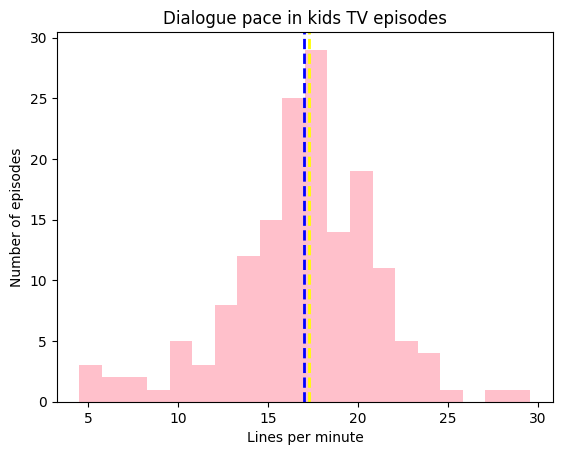

In [13]:
plt.hist(episode_info_df.Lines_per_min, bins=20, color='pink')
plt.xlabel('Lines per minute')
plt.ylabel('Number of episodes')
plt.title('Dialogue pace in kids TV episodes')

# draw where the average is in blue
plt.axvline(episode_info_df.Lines_per_min.mean(), color='blue', linestyle='dashed', linewidth=2)

# draw where the median is in yellow
plt.axvline(episode_info_df.Lines_per_min.median(), color='yellow', linestyle='dashed', linewidth=2)

In [14]:
# fastest and slowest episodes
fastest = episode_info_df.loc[episode_info_df.Lines_per_min == episode_info_df.Lines_per_min.max(), 'Programme'].item()
slowest = episode_info_df.loc[episode_info_df.Lines_per_min == episode_info_df.Lines_per_min.min(), 'Programme'].item()
fastest_per_min_max = episode_info_df.Lines_per_min.max()
slowest_per_min_min = episode_info_df.Lines_per_min.min()

print('Fastest:', fastest, fastest_per_min_max)
print('Slowest:', slowest, slowest_per_min_min)

Fastest: Bluey 29.57345971563981
Slowest: Tee and Mo 4.511278195488722


In [15]:
# Cartoon vs Live Action Show
# just want to find wether the cartoon and live action show difference

In [16]:
style_groupings = episode_info_df.groupby('Style')

style_groupings.Lines_per_min.describe()

# Finding: cartoon and live-action have almost the same dialogue pace.

,count,mean,std,min,25%,50%,75%,max
Style,,,,,,,,
Cartoon,117.0,17.048710,4.109868,4.511278,15.088235,17.226277,19.655172,29.573460
Combination,4.0,11.426806,4.444555,6.484018,8.834745,11.163327,13.755388,16.896552
Live-action,38.0,17.382805,3.804070,9.000000,15.833607,17.614673,19.905134,24.714286
Stop-motion,2.0,15.195652,3.105121,13.000000,14.097826,15.195652,16.293478,17.391304


Text(0, 0.5, 'Number of episodes')

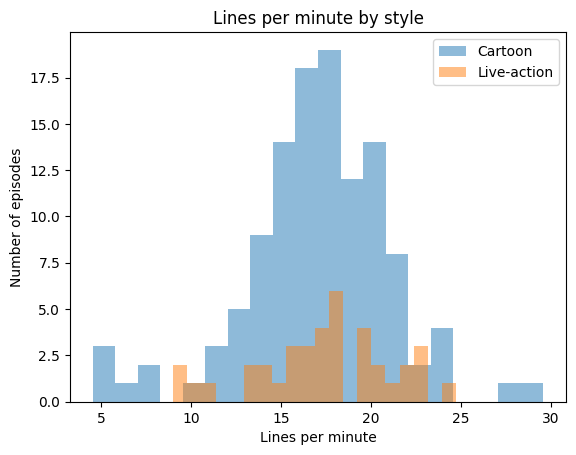

In [17]:
cartoon_df = style_groupings.get_group('Cartoon')
live_action_df = style_groupings.get_group('Live-action')
plt.hist(cartoon_df.Lines_per_min, bins=20, alpha=0.5, label='Cartoon') #alpha: could tweak the bar graph alpha
plt.hist(live_action_df.Lines_per_min, bins=20, alpha=0.5, label='Live-action')
plt.legend()
plt.title('Lines per minute by style')
plt.xlabel('Lines per minute')
plt.ylabel('Number of episodes')

# Finding: cartoon and live-action shows center on the same range, about 15 to 20 lines per minute. 
# Cartoon bars are taller only because there are more cartoon episodes. 

In [18]:
# Line Length (MLU)
episode_info_df.MLU.describe()

# Finding: lines in kids TV are short, about 5 words per line on average.

count    161.000000
mean       5.319814
std        1.241987
min        2.010000
25%        4.550000
50%        5.270000
75%        6.040000
max       10.730000
Name: MLU, dtype: float64

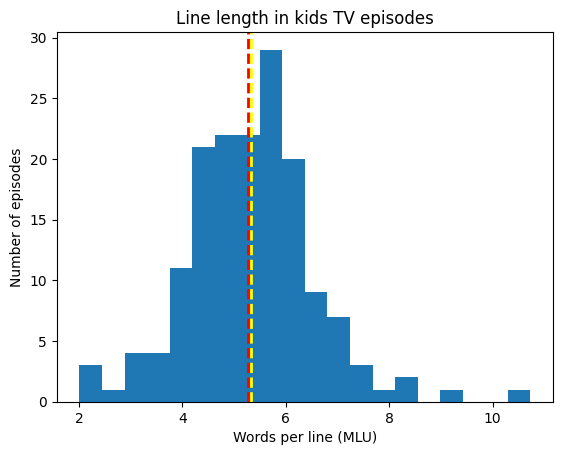

In [19]:
plt.hist(episode_info_df.MLU, bins=20)
plt.xlabel('Words per line (MLU)')
plt.ylabel('Number of episodes')
plt.title('Line length in kids TV episodes')

# mean
plt.axvline(episode_info_df.MLU.mean(), color='yellow', linestyle='dashed', linewidth=2)

# median
plt.axvline(episode_info_df.MLU.median(), color='red', linestyle='dashed', linewidth=2)

In [20]:
# I wanna know wheather faster dialogue will have the shorter lines

In [21]:
pacing_values = episode_info_df[['Length_seconds', 'N_utterances', 'Lines_per_min', 'MLU']]
pacing_values.corr()

,Length_seconds,N_utterances,Lines_per_min,MLU
Length_seconds,1.000000,0.904213,-0.027260,0.095117
N_utterances,0.904213,1.000000,0.340389,0.024070
Lines_per_min,-0.027260,0.340389,1.000000,-0.237341
MLU,0.095117,0.024070,-0.237341,1.000000


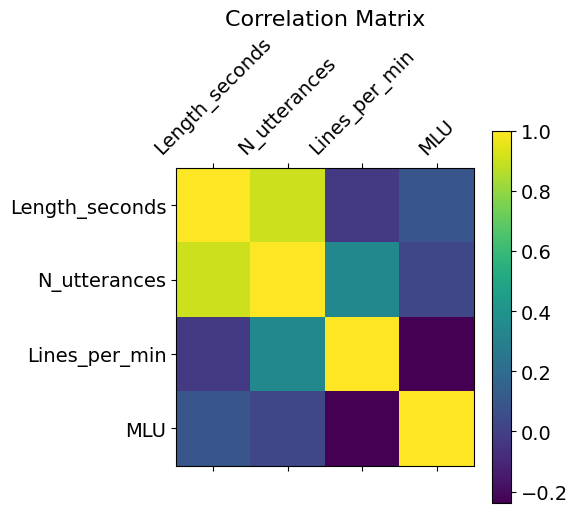

In [22]:
plt.matshow(pacing_values.corr())
plt.xticks(range(pacing_values.select_dtypes(['number']).shape[1]), pacing_values.select_dtypes(['number']).columns, fontsize=14, rotation=45)
plt.yticks(range(pacing_values.select_dtypes(['number']).shape[1]), pacing_values.select_dtypes(['number']).columns, fontsize=14)
cb = plt.colorbar()
cb.ax.tick_params(labelsize=14)
plt.title('Correlation Matrix', fontsize=16);
plt.show()

In [23]:
# Teaser Reference
# at the average pace, how many lines fit in a 30 second teaser?
episode_info_df.Lines_per_min.mean() * 30 / 60

np.float64(8.482435415410883)

In [24]:
# Findings
# 1. Kids TV episodes average about 17 lines per minute. Most episodes fall between 15 and 20.
# 2. "Bluey" is the fastest (about 30 lines per minute). "Tee and Mo" is the slowest (about 4.5).
# 3. Cartoon and live-action shows have almost the same pace, they both about 17 lines per minute).


# 4. At the average pace, a 30 second teaser fits about 8 lines of dialogue.